In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Metro_Traffic.csv")

In [3]:
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [4]:
missing_percent = (df.isnull().mean() * 100).round(2)

print(missing_percent.sort_values(ascending=False))

holiday                99.87
temp                    0.00
rain_1h                 0.00
snow_1h                 0.00
clouds_all              0.00
weather_main            0.00
weather_description     0.00
date_time               0.00
traffic_volume          0.00
dtype: float64


In [5]:
df["holiday"] = df["holiday"].fillna("None")

In [6]:
df.isnull().sum()

holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64

In [7]:
num_cols = df.select_dtypes(include = np.number).columns

In [8]:
for cols in num_cols:
    df[cols] = df[cols].fillna(df[cols].median())

In [9]:
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64


In [10]:
print("Duplicates Rows: ",df.duplicated().sum())
print("Duplicates Rows in percentage: ",df.duplicated().mean() * 100)

Duplicates Rows:  17
Duplicates Rows in percentage:  0.03526678283959837


In [11]:
df = df.drop_duplicates().copy()

In [12]:
df.shape

(48187, 9)

In [13]:
df["date_time"] = pd.to_datetime(df["date_time"])
df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month

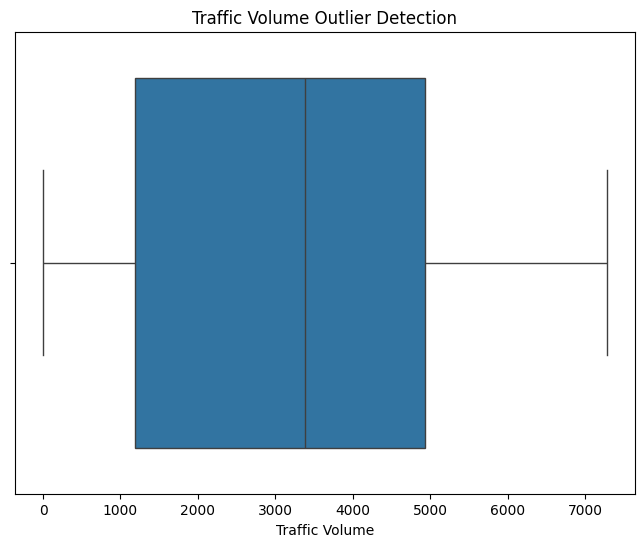

In [14]:
plt.figure(figsize= (8,6))

sns.boxplot(x = df["traffic_volume"])
plt.title("Traffic Volume Outlier Detection")
plt.xlabel("Traffic Volume")

plt.show()

In [15]:
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,hour,day_of_week,month
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,9,1,10
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,10,1,10
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,11,1,10
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,12,1,10
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,13,1,10


calculate the interquartile range (IQR):

In [16]:
q1 = df["traffic_volume"].quantile(0.25)
q3 = df["traffic_volume"].quantile(0.75)

IQR = q3 - q1

lower = q1 - 1.5 * IQR
upper = q3 + 1.5 * IQR

outliers = df[
    (df["traffic_volume"] < lower) |
    (df["traffic_volume"] > upper)
]

print("Lower threshold:", lower)
print("Upper threshold:", upper)
print("Potential outliers:", len(outliers))

Lower threshold: -4418.25
Upper threshold: 10543.75
Potential outliers: 0


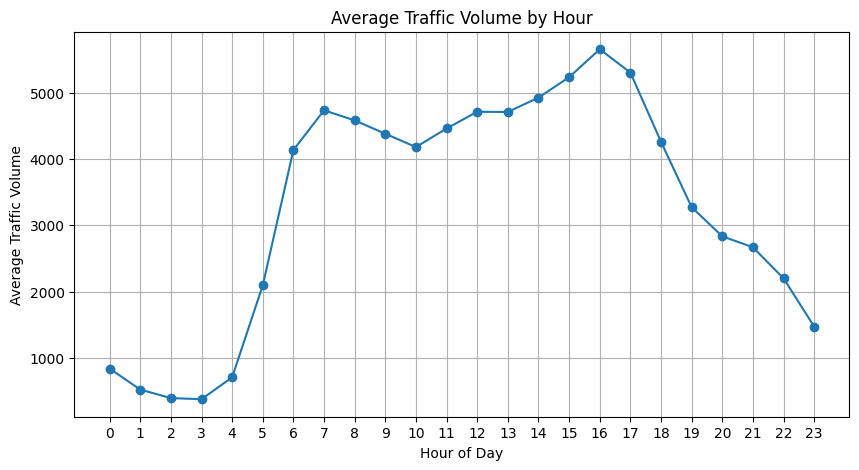

In [17]:
hourly_traffic = df.groupby("hour")["traffic_volume"].mean()

plt.figure(figsize=(10, 5))

plt.plot(hourly_traffic.index,
         hourly_traffic.values,
         marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Volume")
plt.title("Average Traffic Volume by Hour")
plt.xticks(range(24))
plt.grid(True)

plt.show()

Compare weekdays and weekends

In [18]:
df["is_weekend"] = df["day_of_week"].isin([5, 6])

weekend_traffic = df.groupby("is_weekend")["traffic_volume"].mean()

print(weekend_traffic)

is_weekend
False    3533.291791
True     2570.699635
Name: traffic_volume, dtype: float64


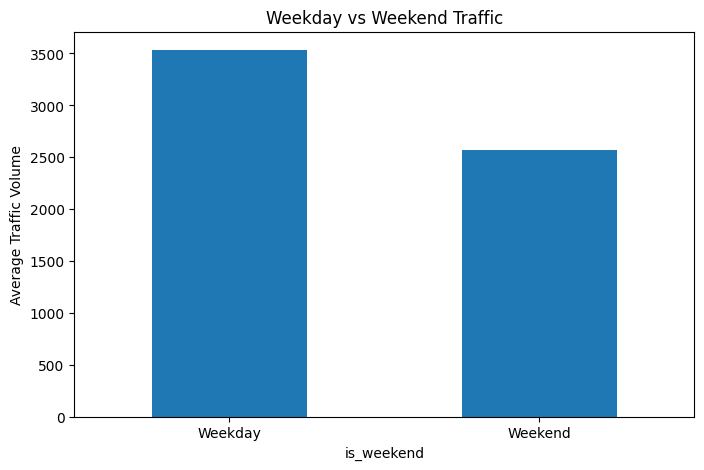

In [20]:
weekend_traffic.plot(kind = "bar", figsize=(8,5))
plt.xticks([0, 1], ["Weekday", "Weekend"], rotation=0)
plt.ylabel("Average Traffic Volume")
plt.title("Weekday vs Weekend Traffic")
plt.show()

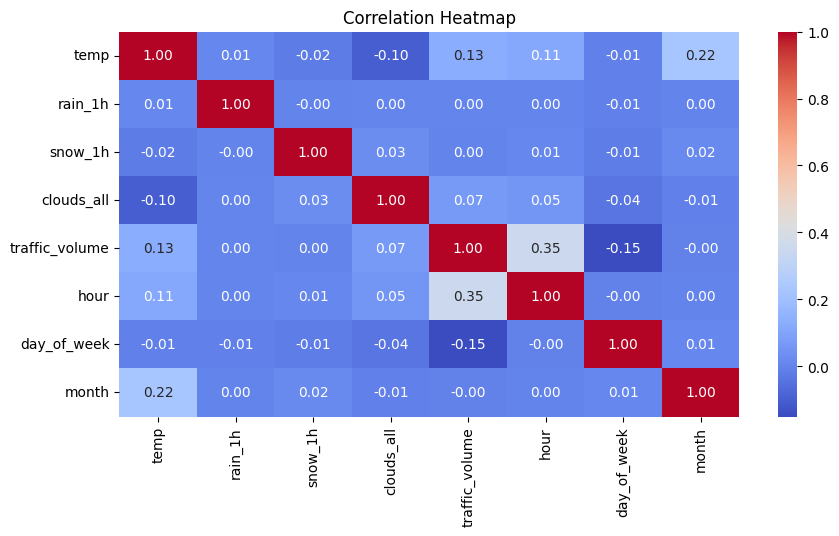

In [27]:
numeric_df = df.select_dtypes(include = np.number)

corr = numeric_df.corr()

plt.figure(figsize=(10,5))

sns.heatmap(corr, 
           annot = True,
           cmap="coolwarm",
           fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [28]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

display(df.head())

Final dataset shape: (48187, 13)

Missing values:
0

Duplicate rows:
0


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,hour,day_of_week,month,is_weekend
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,9,1,10,False
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,10,1,10,False
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,11,1,10,False
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,12,1,10,False
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,13,1,10,False


In [29]:
df.to_csv("traffic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
